# Teste de notebook
## Objetivo: desenvolver um algoritmo que preveja o preco de um veiculo dado sua kilometragem




Carregando o arquivo da base de dados

In [11]:
import pandas as pd
import numpy as np

In [5]:
def open_csv(
    file_path: str,
    required_columns: list
) -> pd.DataFrame:
    try:
        df = pd.read_csv(file_path)
        return df[required_columns]
    except Exception as e:
        raise Exception(e)

In [10]:
data = open_csv("data.csv", ["km", "price"])
data.head()

,km,price
0,240000,3650
1,139800,3800
2,150500,4400
3,185530,4450
4,176000,5250


## Vamos testar a ferramenta primeiro

**Aqui vemos que conseguimos o intercepto e o coeficiente angular mas por enquanto eles nao servem para nada. Como podemos usar eles? E o que eles indicam?**

In [20]:

x_values = data["km"].to_numpy(dtype=float)
y_values = data["price"].to_numpy(dtype=float)

t1, t0 = np.polyfit(x_values, y_values, 1)

print(f"Coeficiente angular (t1): {t1:.4f}")
print(f"Intercepto (t0): {t0:.4f}")

   



Coeficiente angular (t1): -0.0214
Intercepto (t0): 8499.5996


**Como o grafico a baixo demonstra aqui temos uma correlacao entre, quanto maior a kilometragem, menor eh o preco**

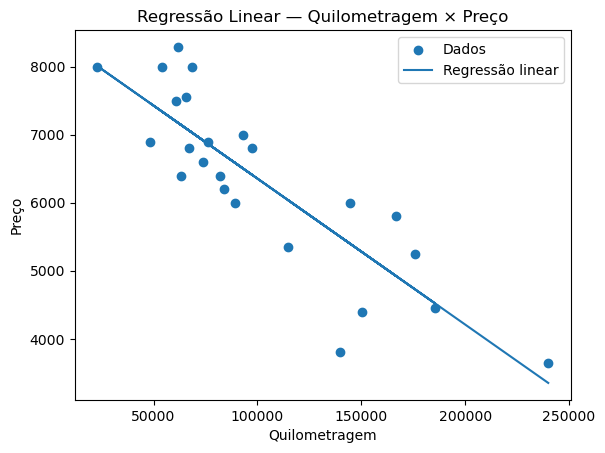

In [21]:
import matplotlib.pyplot as plt
y_pred = t0 + t1 * x_values 
plt.scatter(x_values, y_values, label="Dados")
plt.plot(x_values, y_pred, label="Regressão linear")

plt.xlabel("Quilometragem")
plt.ylabel("Preço")
plt.title("Regressão Linear — Quilometragem × Preço")
plt.legend()
plt.show()

## Vamos testar os valores da minha Regressao Linear utilizando o Gradient Descent agora

In [24]:
from handMade.train import Trainer,  Model

In [25]:
model = Model()
trainer  =  Trainer(data=data, model=model)

**Aqui definimos meu modelo e meu treinador que eu definir na pasta handMade**

In [29]:
# Vamos comecar o treinamento
print("Parametros do meu treinamento")
trainer.gradient_descent()

print(f"\nParametros Polyfit: T0: {t0}, T1: {t1}")

Parametros do meu treinamento
Converged after 17000 epochs with loss: 445645.245071
Final parameters: T0 = 8499.599644963486, T1 = -0.021448963548569965

Parametros Polyfit: T0: 8499.599649933221, T1: -0.02144896359170234


**Como podemos ver a cima temos praticamente os mesmos valores, marcando o fato que meu `gradient_descent()` tem uma parada um pouco mais cedo, entao ele converge um pouco antes da polyfit, geranto um numero final ligeiramente menor**

## Vamos testar os parametros do meu modelo numa previsao agora

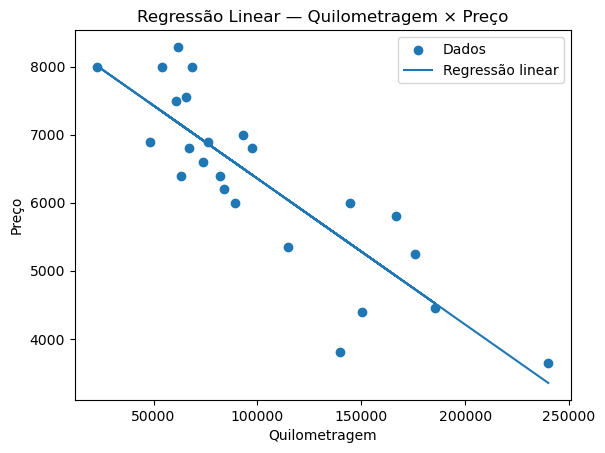

In [31]:
y_pred = model.params[0] + model.params[1] / trainer.scale * x_values 
plt.scatter(x_values, y_values, label="Dados")
plt.plot(x_values, y_pred, label="Regressão linear")

plt.xlabel("Quilometragem")
plt.ylabel("Preço")
plt.title("Regressão Linear — Quilometragem × Preço")
plt.legend()
plt.show()

**Agora podemos ver que ambos os graficos demonstram o mesmo comportamento, quanto maior a kilometragem, menor o preco, e com isso eu provo que meu algoritmo esta realmente aprendendo o padrao da nossa base de dados**

In [1]:
print("Hello, World!")

Hello, World!
